## Load Dataset




In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/mobile_game_inapp_purchases.csv')

print("First 5 rows of the DataFrame:")
print(df.head())

print("\nDataFrame Info:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())

print("\nMissing Values per Column:")
print(df.isnull().sum())

First 5 rows of the DataFrame:
                                 UserID   Age  Gender      Country   Device  \
0  c9889ab0-9cfc-4a75-acd9-5eab1df0015c  49.0    Male       Norway  Android   
1  7c9e413c-ecca-45f2-a780-2826a07952a2  15.0    Male  Switzerland      iOS   
2  fd61e419-1a92-4f43-a8c7-135842ad328a  23.0    Male        China  Android   
3  bdb7f6d1-ff9a-468c-afe7-43f32a94293e  31.0    Male       Mexico  Android   
4  aa7eec14-4846-47b9-b879-9c98038cda04  37.0  Female        India  Android   

       GameGenre  SessionCount  AverageSessionLength SpendingSegment  \
0  Battle Royale             9                 12.83          Minnow   
1     Action RPG            11                 19.39          Minnow   
2       Fighting             9                  8.87          Minnow   
3         Racing            12                 19.56          Minnow   
4  Battle Royale            10                 15.23          Minnow   

   InAppPurchaseAmount  FirstPurchaseDaysAfterInstall Payment

## Data Preprocessing




In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import numpy as np

# 1. Drop irrelevant columns
df_processed = df.drop(columns=['UserID', 'LastPurchaseDate'])
print("Dropped UserID and LastPurchaseDate columns.")

# Identify numerical and categorical columns for imputation
numerical_cols = ['Age', 'InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall']
categorical_cols = ['Gender', 'Country', 'Device', 'GameGenre', 'PaymentMethod']

# 2. Impute missing numerical values with median
for col in numerical_cols:
    if df_processed[col].isnull().any():
        median_val = df_processed[col].median()
        df_processed[col] = df_processed[col].fillna(median_val)
print(f"Imputed numerical columns ({numerical_cols}) with median.")

# 3. Impute missing categorical values with mode
for col in categorical_cols:
    if df_processed[col].isnull().any():
        mode_val = df_processed[col].mode()[0]
        df_processed[col] = df_processed[col].fillna(mode_val)
print(f"Imputed categorical columns ({categorical_cols}) with mode.")

# Verify no more missing values in the imputed columns
print("\nMissing values after imputation:")
print(df_processed[numerical_cols + categorical_cols].isnull().sum())

# 4. Encode the target variable 'SpendingSegment'
le = LabelEncoder()
df_processed['SpendingSegment_Encoded'] = le.fit_transform(df_processed['SpendingSegment'])
print("\nEncoded 'SpendingSegment' target variable.")
print("Original SpendingSegment categories:", le.classes_)
print("Encoded values:", np.unique(df_processed['SpendingSegment_Encoded']))

# 5. One-hot encode other categorical features
onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_features = onehot_encoder.fit_transform(df_processed[categorical_cols])
encoded_df = pd.DataFrame(encoded_features, columns=onehot_encoder.get_feature_names_out(categorical_cols), index=df_processed.index)

df_processed = pd.concat([df_processed.drop(columns=categorical_cols), encoded_df], axis=1)
print("\nOne-hot encoded categorical features.")

# Prepare X and y
X = df_processed.drop(columns=['SpendingSegment', 'SpendingSegment_Encoded'])
y = df_processed['SpendingSegment_Encoded']
print("\nSeparated features (X) and target (y).")

# Identify numerical columns for scaling after one-hot encoding
numerical_features_for_scaling = X.select_dtypes(include=np.number).columns.tolist()

# 7. Standardize numerical features in X
scaler = StandardScaler()
X[numerical_features_for_scaling] = scaler.fit_transform(X[numerical_features_for_scaling])
print("Standardized numerical features in X.")

# 8. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("\nSplit data into training and testing sets (80/20 split, stratified).")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


Dropped UserID and LastPurchaseDate columns.
Imputed numerical columns (['Age', 'InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall']) with median.
Imputed categorical columns (['Gender', 'Country', 'Device', 'GameGenre', 'PaymentMethod']) with mode.

Missing values after imputation:
Age                              0
InAppPurchaseAmount              0
FirstPurchaseDaysAfterInstall    0
Gender                           0
Country                          0
Device                           0
GameGenre                        0
PaymentMethod                    0
dtype: int64

Encoded 'SpendingSegment' target variable.
Original SpendingSegment categories: ['Dolphin' 'Minnow' 'Whale']
Encoded values: [0 1 2]

One-hot encoded categorical features.

Separated features (X) and target (y).
Standardized numerical features in X.

Split data into training and testing sets (80/20 split, stratified).
X_train shape: (2419, 59)
X_test shape: (605, 59)
y_train shape: (2419,)
y_test shape: (605,)


## Build and Train ANN




Number of output classes: 3

ANN Model Summary :


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,115 (70.76 KB)

 Trainable params: 18,115 (70.76 KB)

 Non-trainable params: 0 (0.00 B)


 Compiled successfully.

 Training complete.


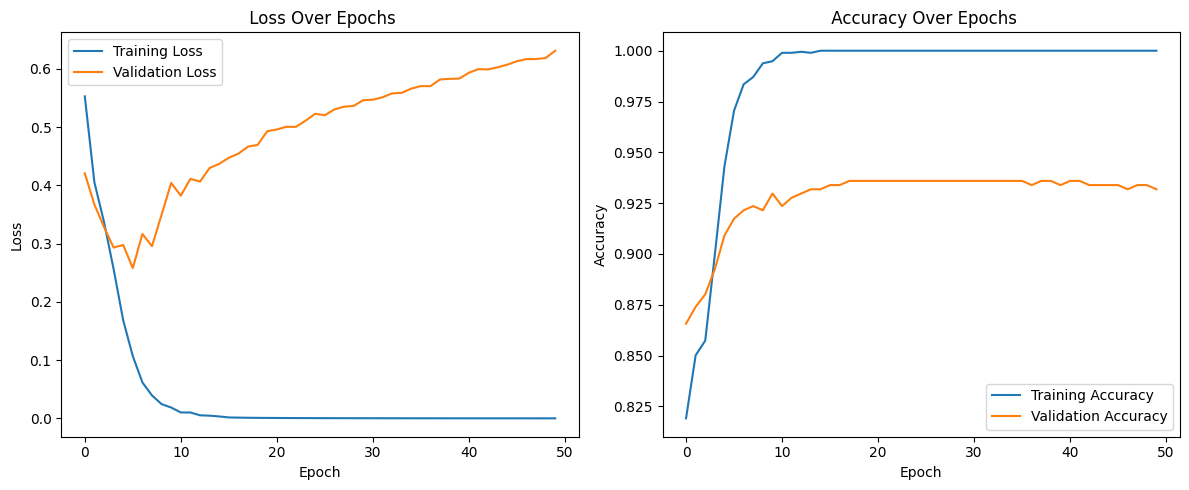

Loss and Accuracy plots.


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import matplotlib.pyplot as plt

# 1. Define the number of output classes
num_classes = y_train.nunique()
print(f"Number of output classes: {num_classes}")

# 2. Create a Sequential model
model_fixed = Sequential()

# 3. Add an explicit Input layer
model_fixed.add(Input(shape=(X_train.shape[1],)))

# 4. Add at least three Dense hidden layers with ReLU activation
model_fixed.add(Dense(128, activation='relu'))
model_fixed.add(Dense(64, activation='relu'))
model_fixed.add(Dense(32, activation='relu'))

# 5. Add a Dense output layer with num_classes units and a softmax activation function
model_fixed.add(Dense(num_classes, activation='softmax'))

# Print model summary to verify architecture
print("\nANN Model Summary :")
model_fixed.summary()

# 6. Compile the model
model_fixed.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("\n Compiled successfully.")

# 7. Train the ANN model
history_fixed = model_fixed.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)
print("\n Training complete.")

# 8. Plot the training and validation loss curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_fixed.history['loss'], label='Training Loss')
plt.plot(history_fixed.history['val_loss'], label='Validation Loss')
plt.title(' Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# 9. Plot the training and validation accuracy curves
plt.subplot(1, 2, 2)
plt.plot(history_fixed.history['accuracy'], label='Training Accuracy')
plt.plot(history_fixed.history['val_accuracy'], label='Validation Accuracy')
plt.title(' Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

print("Loss and Accuracy plots.")

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Initialize and train Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
print("Logistic Regression model trained.")

# Initialize and train K-Nearest Neighbors model
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
print("K-Nearest Neighbors model trained.")

# Initialize and train Random Forest model
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X_train, y_train)
print("Random Forest model trained.")

# Initialize and train Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)
print("Decision Tree model trained.")

# Store models in a dictionary for easy access and evaluation later
models = {
    'Logistic Regression': log_reg,
    'K-Nearest Neighbors': knn,
    'Random Forest': random_forest,
    'Decision Tree': decision_tree
}

print("All traditional machine learning models are trained and stored.")

Logistic Regression model trained.
K-Nearest Neighbors model trained.
Random Forest model trained.
Decision Tree model trained.
All traditional machine learning models are trained and stored.


## Evaluate All Models



Class labels: ['Dolphin' 'Minnow' 'Whale']

Evaluating Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

     Dolphin       1.00      0.71      0.83        82
      Minnow       0.96      1.00      0.98       509
       Whale       0.88      1.00      0.93        14

    accuracy                           0.96       605
   macro avg       0.94      0.90      0.91       605
weighted avg       0.96      0.96      0.96       605



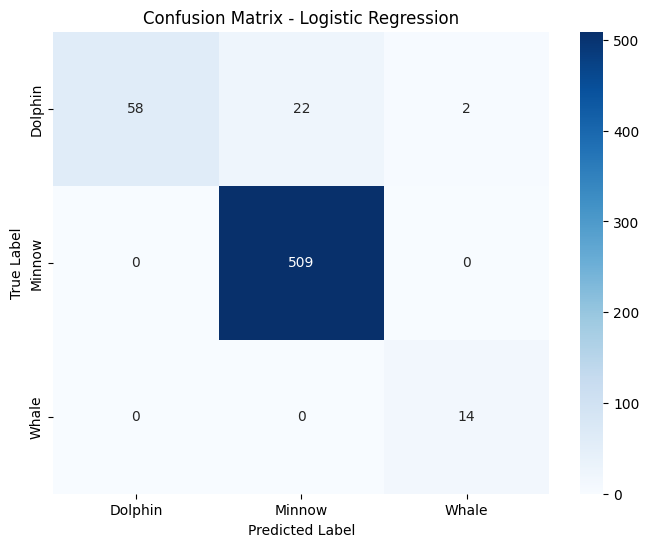


Specificity per class:
  Class Dolphin: 1.0000
  Class Minnow: 0.7708
  Class Whale: 0.9966


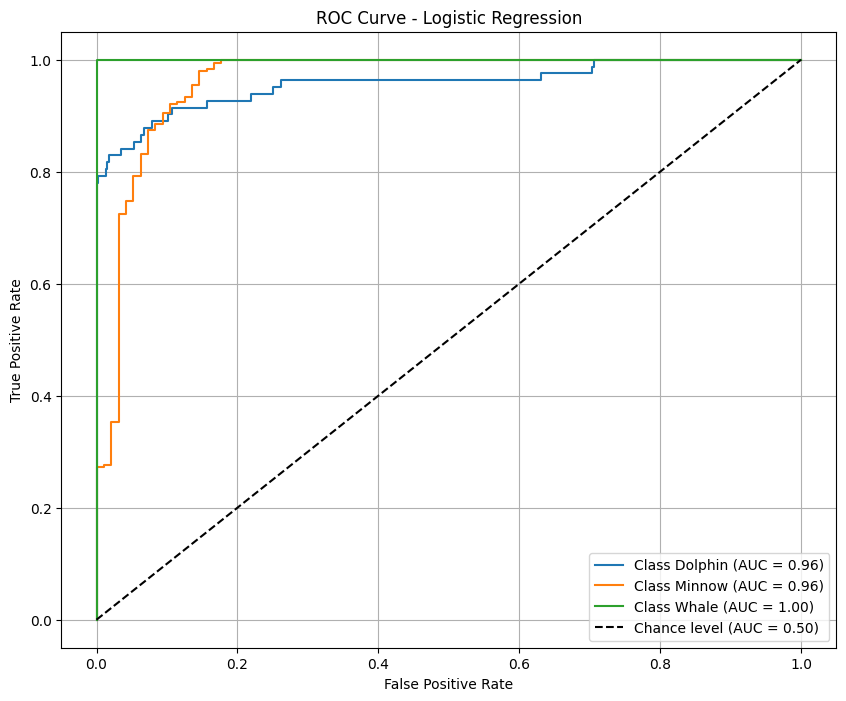


Evaluating Model: K-Nearest Neighbors

Classification Report:
              precision    recall  f1-score   support

     Dolphin       0.16      0.04      0.06        82
      Minnow       0.85      0.97      0.91       509
       Whale       1.00      0.36      0.53        14

    accuracy                           0.83       605
   macro avg       0.67      0.45      0.50       605
weighted avg       0.76      0.83      0.78       605



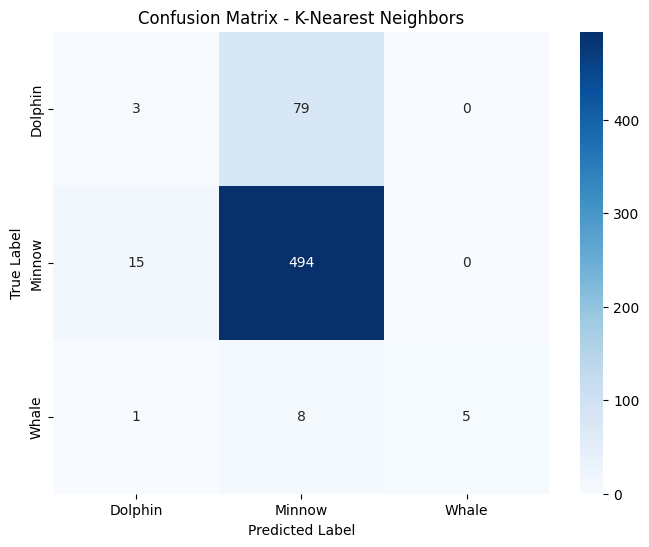


Specificity per class:
  Class Dolphin: 0.9694
  Class Minnow: 0.0938
  Class Whale: 1.0000


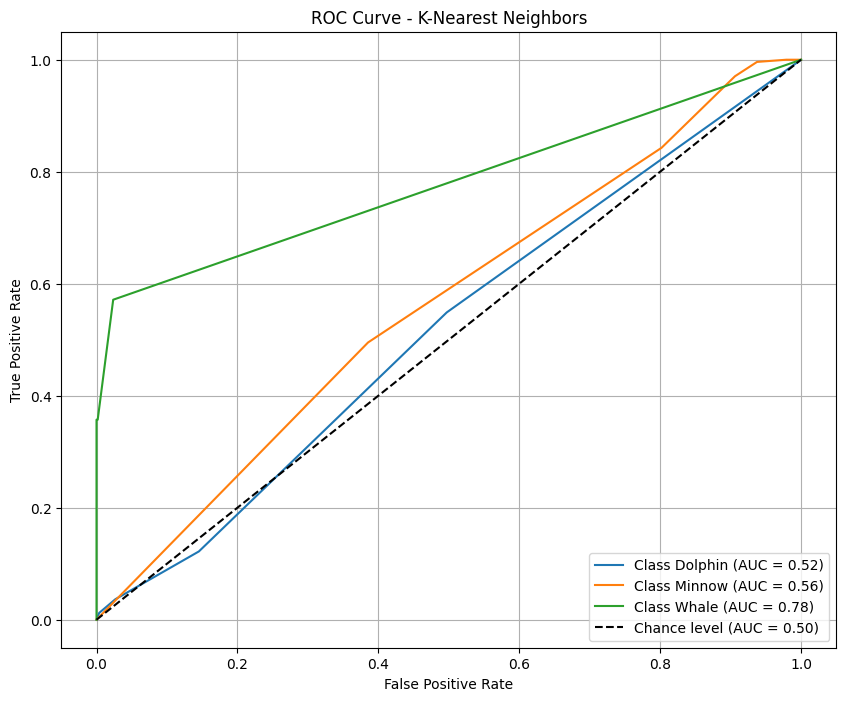


Evaluating Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

     Dolphin       0.97      0.94      0.96        82
      Minnow       0.99      1.00      0.99       509
       Whale       1.00      0.93      0.96        14

    accuracy                           0.99       605
   macro avg       0.99      0.96      0.97       605
weighted avg       0.99      0.99      0.99       605



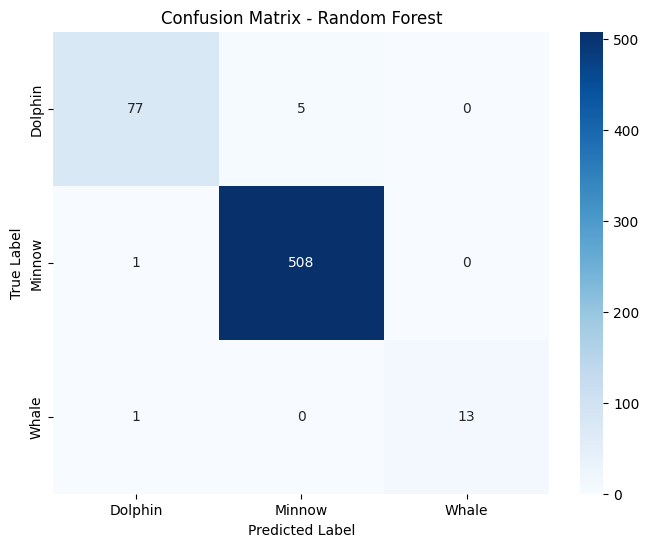


Specificity per class:
  Class Dolphin: 0.9962
  Class Minnow: 0.9479
  Class Whale: 1.0000


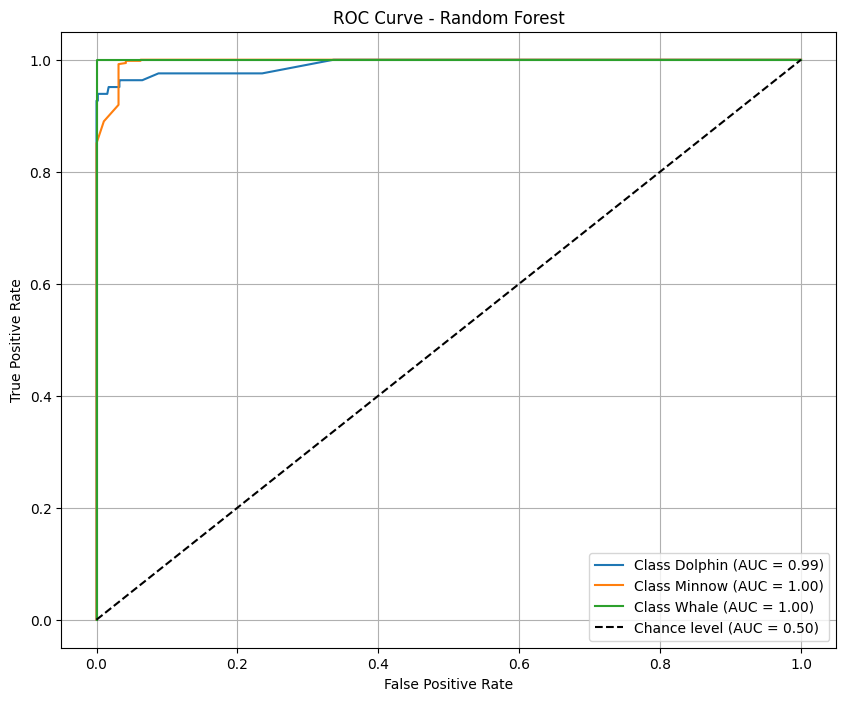


Evaluating Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

     Dolphin       0.93      0.96      0.95        82
      Minnow       0.99      0.99      0.99       509
       Whale       0.93      1.00      0.97        14

    accuracy                           0.98       605
   macro avg       0.95      0.98      0.97       605
weighted avg       0.98      0.98      0.98       605



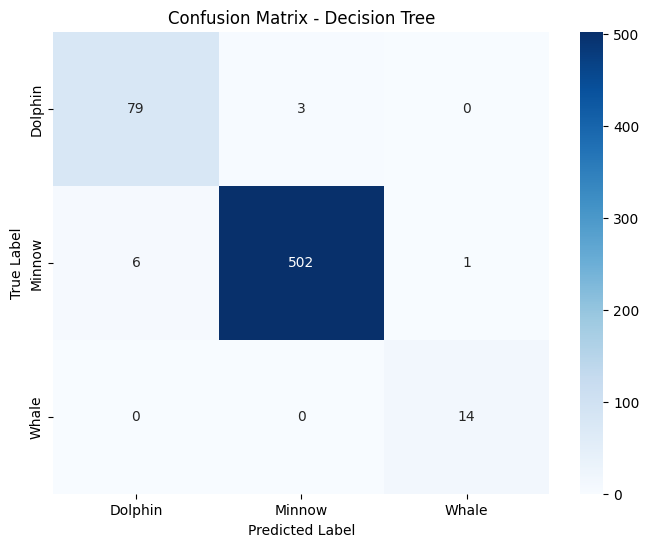


Specificity per class:
  Class Dolphin: 0.9885
  Class Minnow: 0.9688
  Class Whale: 0.9983


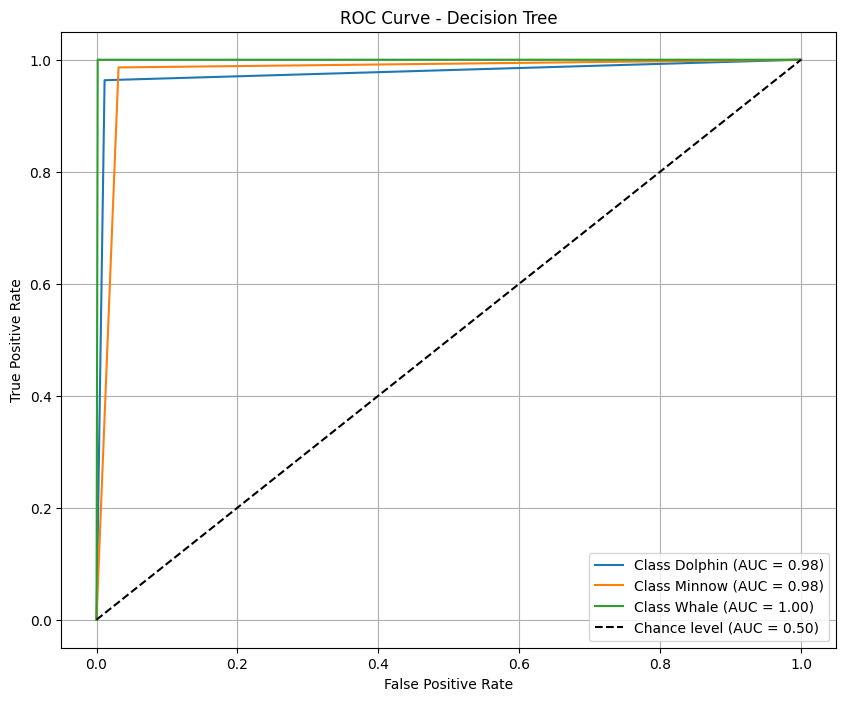


Evaluating Model: ANN
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

Classification Report:
              precision    recall  f1-score   support

     Dolphin       0.87      0.55      0.67        82
      Minnow       0.93      0.99      0.96       509
       Whale       1.00      1.00      1.00        14

    accuracy                           0.93       605
   macro avg       0.93      0.85      0.88       605
weighted avg       0.92      0.93      0.92       605



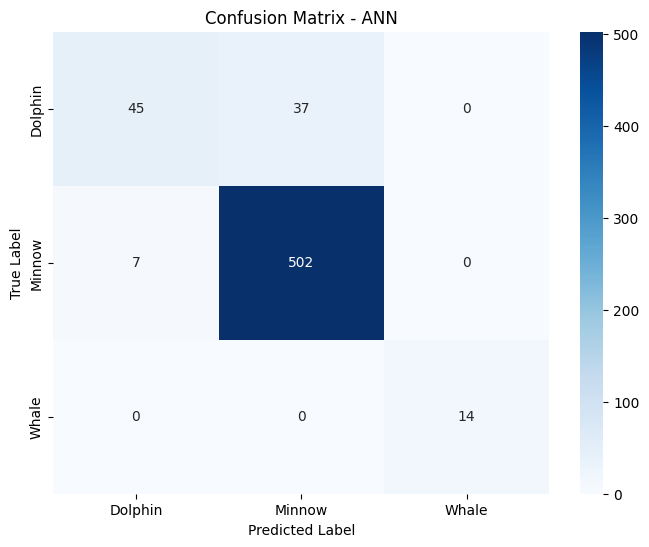


Specificity per class:
  Class Dolphin: 0.9866
  Class Minnow: 0.6146
  Class Whale: 1.0000


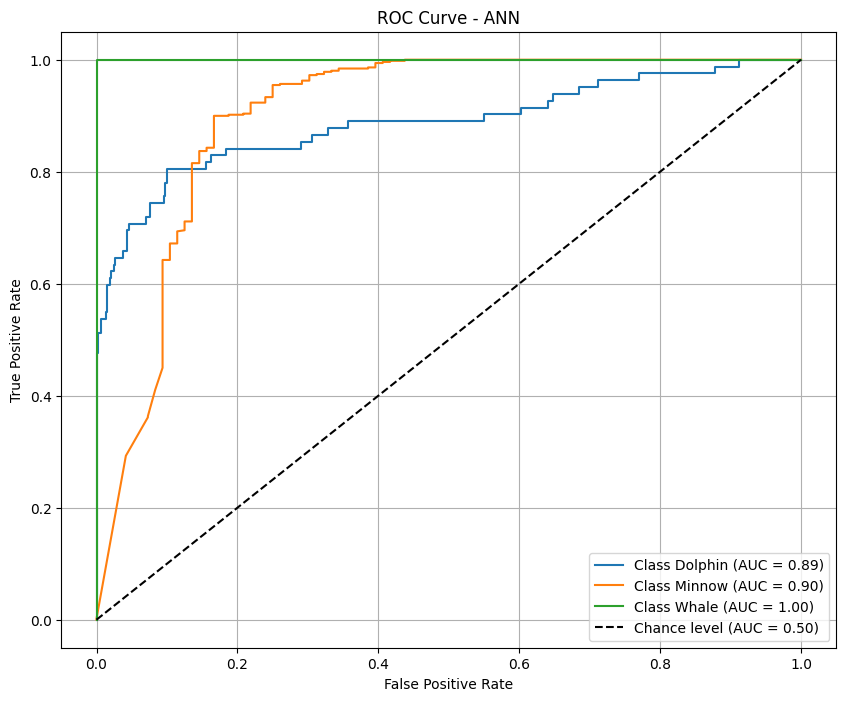

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

# Get class labels from the LabelEncoder used in preprocessing
# Assuming `le` is still available from the preprocessing step
class_labels = le.classes_
print(f"Class labels: {class_labels}")

def evaluate_model(model_name, model, X_test, y_test, num_classes, class_labels):
    print(f"\n{'='*50}")
    print(f"Evaluating Model: {model_name}")
    print(f"{'='*50}")

    # 3a. Obtain predicted class labels and prediction probabilities
    if model_name == 'ANN':
        y_pred_proba = model.predict(X_test)
        y_pred = np.argmax(y_pred_proba, axis=1)
    else:
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)

    # 3b. Print classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=class_labels, zero_division=0))

    # 3c. Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # 3d. Plot the confusion matrix as a heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

    # 3e. Calculate specificity for each class
    print("\nSpecificity per class:")
    for i in range(num_classes):
        TP = cm[i, i]
        FN = np.sum(cm[i, :]) - TP
        FP = np.sum(cm[:, i]) - TP
        TN = np.sum(cm) - TP - FN - FP

        specificity = TN / (TN + FP) if (TN + FP) != 0 else 0
        print(f'  Class {class_labels[i]}: {specificity:.4f}')

    # 3f. For multi-class classification, binarize y_test
    y_test_binarized = label_binarize(y_test, classes=range(num_classes))

    # 3g. Calculate FPR, TPR, and AUC for each class
    plt.figure(figsize=(10, 8))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'Class {class_labels[i]} (AUC = {roc_auc:.2f})')

    # 3h. Plot the ROC curve
    plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.50)')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()



# 4. Iterate through traditional ML models and evaluate
for name, m in models.items():
    evaluate_model(name, m, X_test, y_test, num_classes, class_labels)

# 5. Evaluate the ANN model
evaluate_model('ANN', model, X_test, y_test, num_classes, class_labels)

## Model Comparison and Analysis




Class labels: ['Dolphin' 'Minnow' 'Whale']

Comprehensive Model Comparison Table
                 Model  Accuracy  Precision_MacroAvg  Recall_MacroAvg  F1-Score_MacroAvg  Specificity_Dolphin  Specificity_Minnow  Specificity_Whale  AUC_Dolphin  AUC_Minnow  AUC_Whale
2        Random Forest  0.988430            0.988312         0.955210           0.971205             0.996176            0.947917           1.000000     0.991477    0.996552   1.000000
3        Decision Tree  0.983471            0.952268         0.983221           0.967254             0.988528            0.968750           0.998308     0.975971    0.977499   0.999154
0  Logistic Regression  0.960331            0.944523         0.902439           0.913584             1.000000            0.770833           0.996616     0.957539    0.962078   1.000000
4                  ANN  0.940496            0.965718         0.860479           0.897662             0.996176            0.645833           1.000000     0.879168    0.895332   1.0

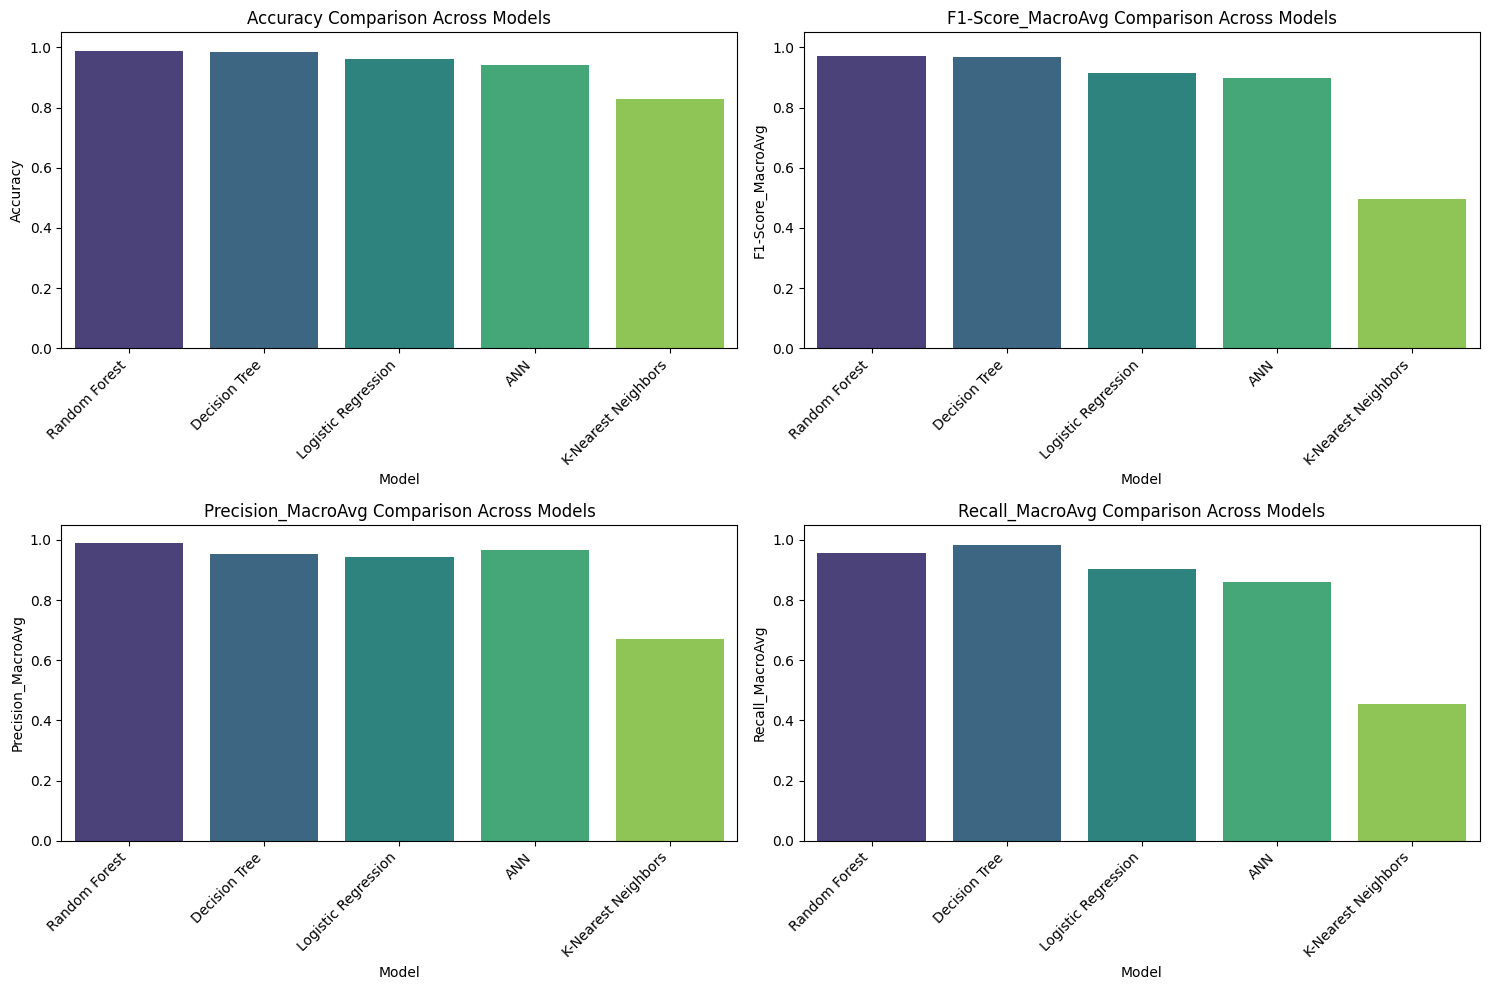

Comparative bar charts.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score
from sklearn.preprocessing import label_binarize
import numpy as np
import pandas as pd

# Get class labels from the LabelEncoder used in preprocessing
class_labels = le.classes_
print(f"Class labels: {class_labels}")

def evaluate_model_and_return_metrics(model_name, model, X_test, y_test, num_classes, class_labels):
    metrics = {'Model': model_name}

    # Obtain predicted class labels and prediction probabilities
    if model_name == 'ANN':
        y_pred_proba = model_fixed.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)
    else:
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)

    # Calculate overall Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    metrics['Accuracy'] = accuracy

    # Classification report for Precision, Recall, F1-Score
    report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True, zero_division=0)
    metrics['Precision_MacroAvg'] = report['macro avg']['precision']
    metrics['Recall_MacroAvg'] = report['macro avg']['recall']
    metrics['F1-Score_MacroAvg'] = report['macro avg']['f1-score']

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    # Specificity for each class
    for i in range(num_classes):
        TP = cm[i, i]
        FN = np.sum(cm[i, :]) - TP
        FP = np.sum(cm[:, i]) - TP
        TN = np.sum(cm) - TP - FN - FP

        specificity = TN / (TN + FP) if (TN + FP) != 0 else 0
        metrics[f'Specificity_{class_labels[i]}'] = specificity

    # ROC Curve and AUC for each class
    y_test_binarized = label_binarize(y_test, classes=range(num_classes))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
        roc_auc = auc(fpr, tpr)
        metrics[f'AUC_{class_labels[i]}'] = roc_auc

    return metrics

# List to store metrics for all models
all_model_metrics = []

# Evaluate traditional ML models
for name, m in models.items():
    model_metrics = evaluate_model_and_return_metrics(name, m, X_test, y_test, num_classes, class_labels)
    all_model_metrics.append(model_metrics)

# Evaluate the ANN model (using model_fixed)
ann_metrics = evaluate_model_and_return_metrics('ANN', model_fixed, X_test, y_test, num_classes, class_labels)
all_model_metrics.append(ann_metrics)

# Convert to DataFrame
metrics_df = pd.DataFrame(all_model_metrics)

# Print and display the comparison table, sorted by Accuracy
print("\n" + "="*70)
print("Comprehensive Model Comparison Table")
print("="*70)
metrics_df_sorted = metrics_df.sort_values(by='Accuracy', ascending=False)
print(metrics_df_sorted.to_string())

# Comparative Bar Charts

# Define metrics to plot
overall_metrics_to_plot = ['Accuracy', 'F1-Score_MacroAvg', 'Precision_MacroAvg', 'Recall_MacroAvg']

plt.figure(figsize=(15, 10))

for i, metric in enumerate(overall_metrics_to_plot):
    plt.subplot(2, 2, i + 1)

    sns.barplot(x='Model', y=metric, data=metrics_df_sorted, palette='viridis', hue='Model', legend=False)
    plt.title(f'{metric} Comparison Across Models')
    plt.ylabel(metric)
    plt.xlabel('Model')
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

print("Comparative bar charts.")